<a href="https://colab.research.google.com/github/RohitKumar2705/LANGGRAPH/blob/main/STRUCTURED_OUTPUT_AGENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
!pip install -U langchain langchain-community langchain-core langgraph tavily-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.5/112.5 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.7/506.7 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.1/168.1 kB 7.8 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.2.19
    Uninstalling langchain-core-1.2.19:
      Successfully uninstalled langchain-core-1.2.19
  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.1.2
    Uninstalling langgraph-1.1.2:
      Successfully uninstalled langgraph-1.1.2
  Attempting uninstall: langchain
    Found existing installation: langchain 1.2.12
    Uninstalling langchain-1.2.12:
      Successfully uninstalled langchain-1.2.12


In [11]:
from langchain_community.tools.tavily_search import TavilySearchResults
from langchain_core.tools import tool
from pydantic import BaseModel, Field
from langgraph.graph import MessagesState, StateGraph, END
from langgraph.prebuilt import ToolNode
from langchain_core.messages import HumanMessage
import os

In [18]:
os.environ["GROQ_API_KEY"] = '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'
os.environ["TAVILY_API_KEY"] = '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'

In [53]:
from langchain_groq import ChatGroq
llm=ChatGroq(model_name="llama3-8b-8192")

In [38]:
tavily_tools = TavilySearchResults()

In [39]:
@tool
def get_city_details(prompt):
    "Should do a web search to find the required city details"
    response = tavily_tool.invoke(prompt)
    return response

In [40]:
tools = [get_city_details]

In [41]:
model_with_tools = llm.bind_tools(tools)

In [42]:
class CityDetails(BaseModel):
  """ respond to the user with this """
  state_name:str = Field(description="State capital of the city")
  state_capital: str = Field(description="State capital of the city")
  country_name: str = Field(description="Country name of the city")
  country_capital: str = Field(description="Country capital of the city")

In [43]:
class AgentState(MessagesState):
  final_response:CityDetails

In [44]:
model_with_structured_output = llm.with_structured_output(CityDetails)


In [45]:
def call_model(state:AgentState):
  print(f"this is 01 input from call model {state}")
  response = model_with_tools.invoke(state['messages'])
  print(f"this is 02 response from call model {response}")
  return {"messages":[response]}

In [46]:
def should_continue(state:AgentState):
  messages = state["messages"]
  last_message = messages[-1]
  if not last_message.tool_calls:
    return "respond"
  else:
    return "continue"

In [47]:
def respond(state: AgentState):
    print(f"here is 03 state from respond {state}")
    response = model_with_structured_output.invoke([HumanMessage(content=state['messages'][-1].content)])
    # We return the final answer
    print(f"this is 04 response from respond{response}")
    return {"final_response": response}

In [48]:
# define a new graph
workflow = StateGraph(AgentState)
workflow.add_node("llm",call_model)
workflow.add_node("tools",ToolNode(tools))
workflow.add_node("respond",respond)
workflow.set_entry_point("llm")
# We now add a conditional edge
workflow.add_conditional_edges(
    "llm",

    should_continue,
    {
        "continue": "tools",
        "respond": "respond",
    },
)

workflow.add_edge("tools", "llm")
workflow.add_edge("respond", END)
graph = workflow.compile()

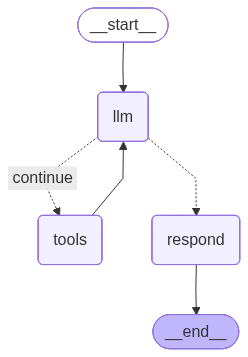

In [49]:
from IPython.display import Image, display
# View
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
answer = graph.invoke(input={"messages": [("human", "Tell me about the city details for gwalior?")]})['final_resp

In [ ]:
answer